In [2]:
import re
import unicodedata
from pathlib import Path
from collections import defaultdict, Counter
import pandas as pd
import numpy as np
import rasterio
import zipfile
import io
import json
import matplotlib.pyplot as plt
import sys

IN_FILE  = Path("datasets/resultset.xlsx")
OUT_FILE = Path("datasets/fineli_head_medians.xlsx")
HEAD_FINELLI_NO_LEMMATIZATION = Path("datasets/fineli_head_medians_no_lemmatization.xlsx")
NUMBERS_FILE = Path("datasets/fineli_pre_processed.xlsx")

# Note: zip files are not in git, download them independently and add them to the directory manually
# Source for this zip: https://drive.google.com/file/d/1Dmnco2Bmm--AGRcdxlFaOXOF3K1d2PzK/view?usp=sharing
SUOMI24_CORPUS_01_06_ZIP_PATH = Path("corpus_files/Parsed_data_1_6.zip")
BATCH_SIZE = 500

LESS_THAN_REPLACEMENT_VALUE = 0.05  # "<0.1" is treated as 0.05

In [3]:
def to_number(value):
    """'12.5' -> 12.5, '<0.1' -> 0.05, 'N/A' or empty -> NaN"""
    if pd.isna(value):
        return np.nan
    value = str(value).strip().replace(',', '.')  # In case '12,5' -> '12.5'
    if value.upper() in {'N/A', 'NA', '-', ''}:
        return np.nan
    if value.startswith('<'):  # '<0.1' -> '0.05'
        return LESS_THAN_REPLACEMENT_VALUE
    try:
        return float(value)
    except ValueError:
        return np.nan


def head_term(name):
    """'Ahven, paistettu voissa' -> 'ahven'"""
    head = str(name).split(',')[0]  # text before the first comma
    head = head.split('/')[0]  # first alternative only, 'Aromisuola/yrttisuola 71 %' -> 'aromisuola'
    head = re.split(r'\d', head)[0]  # cut at the first number, 'kasvirasvalevite 70 %' -> 'kasvirasvalevite'
    head = unicodedata.normalize('NFC', head)  # consistent å/ä/ö for later matching
    head = re.sub(r'\s+', ' ', head).strip().lower()  # replace multiple whitespaces with single whitespaceS
    return head

In [4]:
from simplemma import Lemmatizer
from simplemma.strategies import DictionaryLookupStrategy
from simplemma.strategies.dictionaries import DefaultDictionaryFactory

lemmatizer = Lemmatizer(
    lemmatization_strategy=DictionaryLookupStrategy(dictionary_factory=DefaultDictionaryFactory())
)


KEEP_AS_IS = {'tee', 'voi'}   # already the right lemma, but the lemmatizer reads them as verbs

def lemmatize_word(word):
    """'ahvenet' -> 'ahven', 'tee' -> 'tee' (not changed: no inflection ending)"""
    if not word or word in KEEP_AS_IS:
        return word
    return lemmatizer.lemmatize(word, lang='fi').lower()


def lemmatize_term(term):
    """'ahvenet foliossa' -> 'ahven folio', 'ateria-ainekset' -> 'ateria-aines'"""
    return ' '.join('-'.join(lemmatize_word(part) for part in word.split('-'))
                    for word in term.split(' '))

print(lemmatize_term('ahvenet foliossa'))  # expect: ahven folio
print(lemmatize_term('herneet'))  # expect: herne
print(lemmatize_term('ateria-ainekset'))  # check how the hyphen is handled (expect: ateria-aines)
print(lemmatize_term('tee'))  # expect: tee
print(lemmatize_term('voi'))  # expect: voi

ahven folio
herne
ateria-aines
tee
voi


In [5]:
def read_fineli_raw(in_file):
    return pd.read_excel(in_file, dtype=str)

def convert_to_numbers(raw):
    nutrient_cols = [c for c in raw.columns if c not in ('id', 'name')]
    numbers = raw.copy()
    numbers[nutrient_cols] = raw[nutrient_cols].apply(lambda col: col.map(to_number))
    return numbers

def calculate_medians(numbers):
    df = numbers.drop(columns='id')
    df['name'] = df['name'].map(head_term)
    df = df[df['name'] != '']

    lemma_map = {head: lemmatize_term(head) for head in df['name'].unique()}
    df['name'] = df['name'].map(lemma_map)

    return df.groupby('name').median()

def calculate_medians_no_lemmatization(numbers):
    df = numbers.drop(columns='id')
    df['name'] = df['name'].map(head_term)
    return df.groupby('name').median()

def load_fineli_dataset(in_file=IN_FILE, numbers_file=NUMBERS_FILE, out_file=OUT_FILE):
    raw = read_fineli_raw(in_file)

    numbers = convert_to_numbers(raw)
    # numbers.to_excel(numbers_file, index=False)

    medians = calculate_medians(numbers)
    medians.to_excel(out_file)
    return medians

In [ ]:
fineli = load_fineli_dataset()
print("\n", fineli)


fineli_lemmas = set(fineli.index)
fineli_dict = fineli.fillna(0)[~fineli.index.duplicated(keep='first')].to_dict('index')

c:\Users\kaspe\git\uni-projects\NLP_26_PROJECT_10\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")



                     energia, laskennallinen (kJ)  rasva (g)  \
name                                                          
ahven                                 597.447244   6.642549   
ahven folio                           495.981167   4.080596   
amarantti                            1545.439941   7.000000   
ananas                                270.299995   0.306000   
ananassalsa                           208.769466   0.358155   
...                                          ...        ...   
wokattu kasvis                        362.226265   6.849243   
yrtti                                 108.538630   0.513268   
yrttilevite                          1589.106688  40.113636   
äidinmaidonkorvike                   1180.312120  14.262000   
äidinmaito                            273.049988   3.495000   

                    hiilihydraatti imeytyvä (g)  proteiini (g)  alkoholi (g)  \
name                                                                           
ahven             

In [ ]:
import gzip, io, json, os, zipfile
from collections import Counter
from pathlib import Path

fineli_lemmas = set(fineli.index)
fineli_dict = (fineli.fillna(0)[~fineli.index.duplicated(keep='first')]
                     .to_dict('index'))

# For multi-word foods such as "ahven folio" (longest match wins)
MAX_NGRAM = max(len(f.split(' ')) for f in fineli_lemmas)
FIRST_WORDS = {f.split(' ')[0] for f in fineli_lemmas}

OUT_DIR = Path("datasets/parsed")
OUT_DIR.mkdir(parents=True, exist_ok=True)


def find_foods(lemmas):
    """lemmas: list of lowercase str -> Counter({food: n_occurrences})"""
    found, i, n = Counter(), 0, len(lemmas)
    while i < n:
        if lemmas[i] in FIRST_WORDS:
            for k in range(min(MAX_NGRAM, n - i), 0, -1):
                cand = ' '.join(lemmas[i:i + k])
                if cand in fineli_lemmas:
                    found[cand] += 1
                    i += k
                    break
            else:
                i += 1
        else:
            i += 1
    return found


def lower_list(xs):
    return [str(w).lower() for w in (xs or [])]


def make_message(idx, date, raw_tokens, lemmas, foods):
    return {
        "idx": idx,  # 0 = thread start, 1...n = comments
        "date": date,
        "text": ' '.join(map(str, raw_tokens or [])),
        "lemmas": ' '.join(lemmas),
        "foods": dict(foods),
    }


def process_thread(d, out_f, stats):
    date = str(d.get("date") or "")
    month = date[:7]
    if len(month) != 7:
        return

    title = d.get("title") or ""
    title_lem = lower_list(d.get("orig_msg_lemmatized"))
    comments = d.get("comments") or []

    # Monthly totals over all threads
    # (could probably be removed but decided to add to see better if the script works)
    s = stats.setdefault(month, Counter())
    s["threads"] += 1
    s["comments"] += len(comments)
    s["tokens"] += len(title_lem)

    title_foods = find_foods(title_lem)
    thread_foods = Counter(title_foods)
    messages = []
    if title_foods:
        messages.append(make_message(0, date, d.get("orig_msg"), title_lem, title_foods))

    for i, c in enumerate(comments, start=1):
        c_lem = lower_list(c.get("orig_msg_lemmatized"))
        s["tokens"] += len(c_lem)
        f = find_foods(c_lem)
        if f:
            thread_foods.update(f)
            messages.append(make_message(i, c.get("date") or date,
                                         c.get("orig_msg"), c_lem, f))

    if not thread_foods:
        return
    s["matched_threads"] += 1

    out_f.write(json.dumps({
        "thread_id": d.get("thread_id"),
        "topic": d.get("topic_names"),
        "date": date,
        "month": month,
        "title": title,
        "title_lemmas": ' '.join(title_lem),
        "title_n_tokens": len(title_lem),
        "title_n_chars": len(title),
        "n_comments": len(comments),
        "foods": dict(thread_foods),  # total mentions, title + comments
        "foods_in_title": sorted(title_foods),
        "messages": messages,
    }, ensure_ascii=False) + "\n")


def parse_zip(zip_path):
    zip_path = Path(zip_path)
    with zipfile.ZipFile(zip_path) as z:
        files = [f for f in z.namelist() if f.endswith("with_comments.txt")]
        for file_name in files:
            tag = file_name.split('/')[-2]
            out_path = OUT_DIR / f"{zip_path.stem}_{tag}.jsonl.gz"
            stats_path = OUT_DIR / f"{zip_path.stem}_{tag}_stats.json"
            if out_path.exists() and stats_path.exists():
                print(f"Skipping {file_name} (already parsed)")
                continue

            print(f"Processing {file_name}")
            tmp = Path(str(out_path) + ".tmp")
            stats = {}
            with z.open(file_name) as raw, io.TextIOWrapper(raw, encoding="utf-8") as text, \
                 gzip.open(tmp, "wt", encoding="utf-8") as out_f:
                for n, line in enumerate(text):
                    line = line.strip()
                    if not line:
                        continue
                    try:
                        d = json.loads(line)
                    except json.JSONDecodeError:
                        continue
                    if n == 0:
                        print("  keys:", list(d.keys()))
                        print("  title:", d.get("title"), "| orig_msg:", d.get("orig_msg"))
                    process_thread(d, out_f, stats)

            os.replace(tmp, out_path)   # file only appears once it is complete
            with open(stats_path, "w", encoding="utf-8") as f:
                json.dump({m: dict(c) for m, c in stats.items()}, f)


Processing Parsed_data/1/threads_with_comments.txt
  keys: ['date', 'comment_id', 'parent_comment_id', 'quoted_comment_id', 'thread_id', 'title', 'msg_type', 'topic_names', 'thread_start_datetime', 'orig_msg', 'orig_msg_lemmatized', 'comments']
  title: Hyvää uutta vuotta kaikille Hondailijoille | orig_msg: ['Hyvää', 'uutta', 'vuotta', 'kaikille', 'Hondailijoille']
Processing Parsed_data/2/threads_with_comments.txt
  keys: ['date', 'comment_id', 'parent_comment_id', 'quoted_comment_id', 'thread_id', 'title', 'msg_type', 'topic_names', 'thread_start_datetime', 'orig_msg', 'orig_msg_lemmatized', 'comments']
  title: Näin Porissa! | orig_msg: ['Näin', 'Porissa', '!']
Processing Parsed_data/3/threads_with_comments.txt
  keys: ['date', 'comment_id', 'parent_comment_id', 'quoted_comment_id', 'thread_id', 'title', 'msg_type', 'topic_names', 'thread_start_datetime', 'orig_msg', 'orig_msg_lemmatized', 'comments']
  title: 124td250 ääni oikealta edestä? | orig_msg: ['124td250', 'ääni', 'oikealta

In [ ]:
parse_zip(SUOMI24_CORPUS_01_06_ZIP_PATH)

In [32]:
import glob


def load_monthly_counts():
    """month x food table of mention counts, read from the parsed files."""
    rows = []
    for p in glob.glob(str(OUT_DIR / "*.jsonl.gz")):
        with gzip.open(p, "rt", encoding="utf-8") as f:
            for line in f:
                r = json.loads(line)
                for food, n in r["foods"].items():
                    rows.append((r["month"], food, n))
    return (pd.DataFrame(rows, columns=["month", "food", "n"])
              .groupby(["month", "food"])["n"].sum().unstack(fill_value=0))


counts = load_monthly_counts()
# print(counts.head(1))

food_nutrients = pd.DataFrame.from_dict(fineli_dict, orient='index')
# for each month sum of nutrients (times the food was mentioned * nutrition per food)
monthly_nutrition_df = counts.dot(food_nutrients.loc[counts.columns])

print("Total counts of top 10 foods:")
print(counts.sum().nlargest(10))

Total counts of top 10 foods:
food
voi      74149
vesi     52152
kieli    37637
tee      35684
sydän    25894
kala     23856
veri     18698
kani     18108
viina    16181
liha     15658
dtype: int64


In [29]:
# print(monthly_nutrition_df.head(2))

In [15]:
def draw_monthly_nutrition_intake(monthly_df):
    """
    Draw monthly intake evolution of nutrients.
    monthly_df: DataFrame, index = 'YYYY-MM', columns = nutrient names.
    """
    final_results_df = monthly_df.copy()
    final_results_df.index.name = 'Month'
    final_results_df = final_results_df.sort_index()
    final_results_df.index = final_results_df.index.astype(str)

    nutrient_groups = {
        "Energy (kJ)": [
            'energia, laskennallinen (kJ)'
        ],
        "Main Macros (g)": [
            'proteiini (g)', 'hiilihydraatti imeytyvä (g)', 'rasva (g)', 'alkoholi (g)'
        ],
        "Carbs, Sugars & Fibers (g)": [
            'sokerit (g)', 'fruktoosi (g)', 'galaktoosi (g)', 'glukoosi (g)',
            'laktoosi (g)', 'maltoosi (g)', 'sakkaroosi (g)', 'tärkkelys (g)',
            'kuitu, kokonais- (g)', 'kuitu veteen liukenematon (g)',
            'polysakkaridi, vesiliukoinen ei-selluloosa (g)', 'sokerialkoholi (g)'
        ],
        "Fatty Acids (g)": [
            'rasvahapot yhteensä (g)', 'rasvahapot monityydyttymättömät (g)',
            'rasvahapot yksittäistyydyttymättömät cis (g)', 'rasvahapot tyydyttyneet (g)',
            'rasvahapot trans (g)', 'rasvahapot n-3 monityydyttymättömät (g)',
            'rasvahapot n-6 monityydyttymättömät (g)', 'orgaaniset hapot (g)', 'tryptofaani (mg)'
        ],
        "Specific Fats & Cholesterol (mg)": [
            'rasvahappo 18:2 cis,cis n-6 (linolihappo) (mg)',
            'rasvahappo 18:3 n-3 (alfalinoleenihappo) (mg)',
            'rasvahappo 20:5 n-3 (EPA) (mg)', 'rasvahappo 22:6 n-3 (DHA) (mg)',
            'kolesteroli (GC) (mg)', 'sterolit (mg)'
        ],
        "Minerals & Salts (mg)": [
            'kalsium (mg)', 'rauta (mg)', 'kalium (mg)', 'magnesium (mg)',
            'natrium (mg)', 'suola (mg)', 'fosfori (mg)', 'sinkki (mg)'
        ],
        "Minerals & Salts (µg)": [
            'jodidi (jodi) (µg)', 'seleeni (µg)',
        ],
        "Vitamins (mg)": [
            'C-vitamiini (mg)', 'E-vitamiini alfatokoferoli (mg)',
            'niasiiniekvivalentti NE (mg)',
            'niasiini (nikotiinihappo + nikotiiniamidi) (mg)',
            'pyridoksiini vitameerit (vetykloridi) (B6) (mg)',
            'riboflaviini (B2) (mg)', 'tiamiini (B1) (mg)'
        ],
        "Vitamins (µg)": [
            'A-vitamiini RAE (µg)', 'B12-vitamiini (kobalamiini) (µg)',
            'D-vitamiini (µg)', 'K-vitamiini (µg)', 'folaatti, kokonais- (µg)',
            'karotenoidit (µg)'
        ]
    }

    for group_name, columns in nutrient_groups.items():
        valid_cols = [col for col in columns if col in final_results_df.columns]

        if not valid_cols:
            print(f"Skipping {group_name} because none of those columns exist in the dataframe.")
            continue

        plt.figure(figsize=(21, 7))

        for col in valid_cols:
            plt.plot(final_results_df.index, final_results_df[col], marker='o', label=col)

        plt.title(f"Monthly Evolution: {group_name}", fontsize=16, fontweight='bold')
        plt.xlabel("Month", fontsize=12)
        plt.ylabel("Total nutrition (100g per mention)", fontsize=12)
        plt.xticks(rotation=45, ha='right')
        plt.plot([], [], ' ', label="Each time a food is mentioned,\nthe total amount is appended\nby the nutrient amount in\n100 grams of the food")
        plt.legend(loc='upper left', bbox_to_anchor=(1, 1), borderaxespad=0.)

        plt.grid(True, linestyle='--', alpha=0.6)

        plt.tight_layout()
        plt.show()

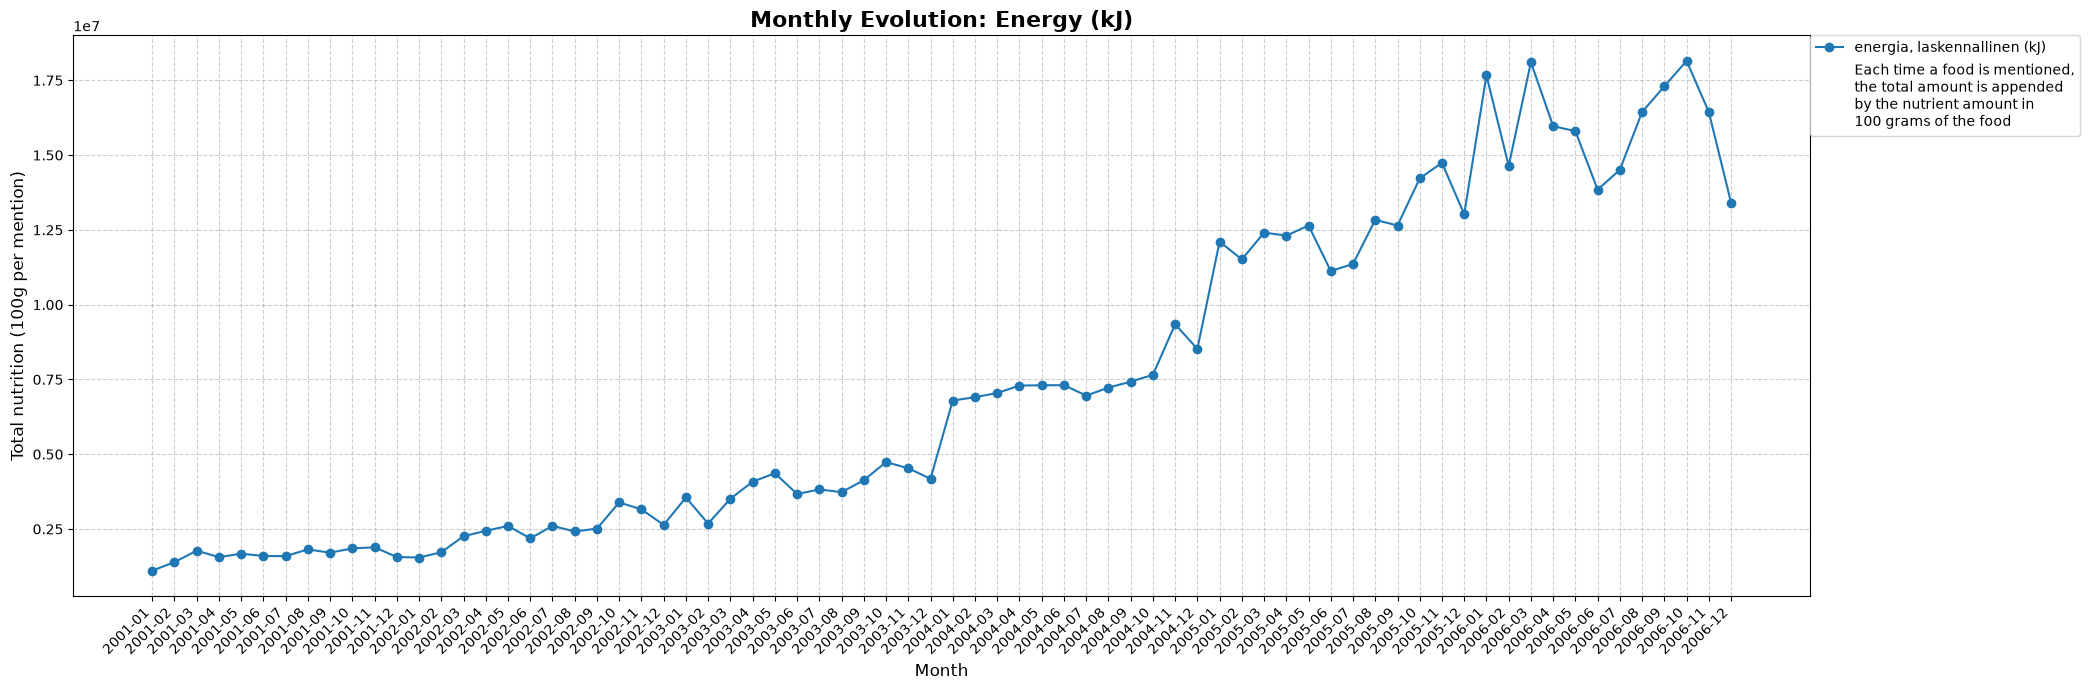

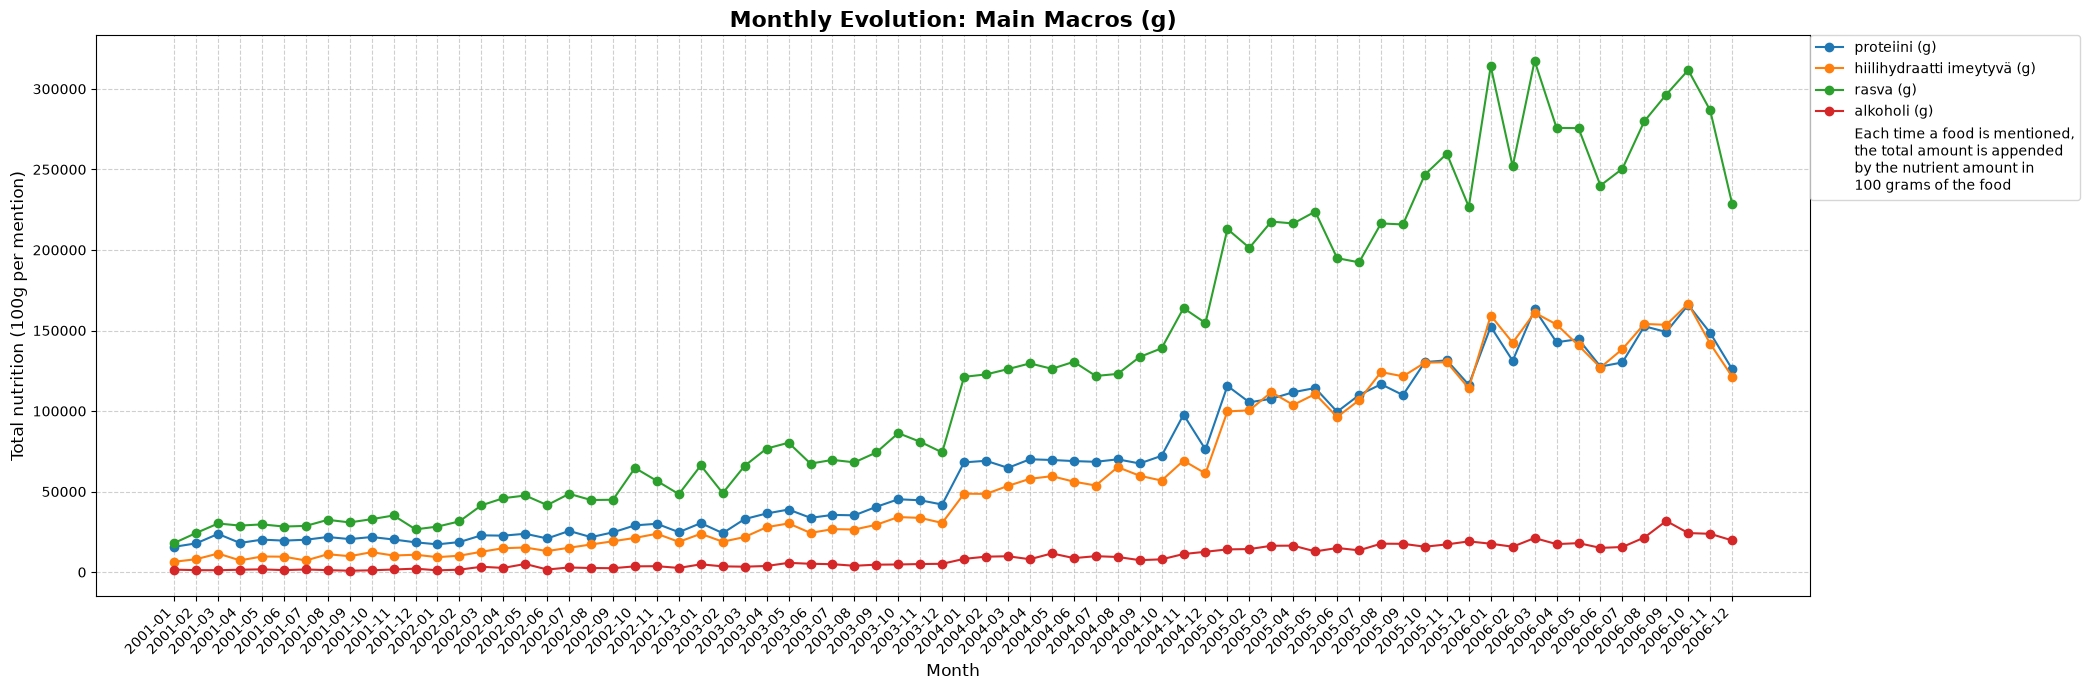

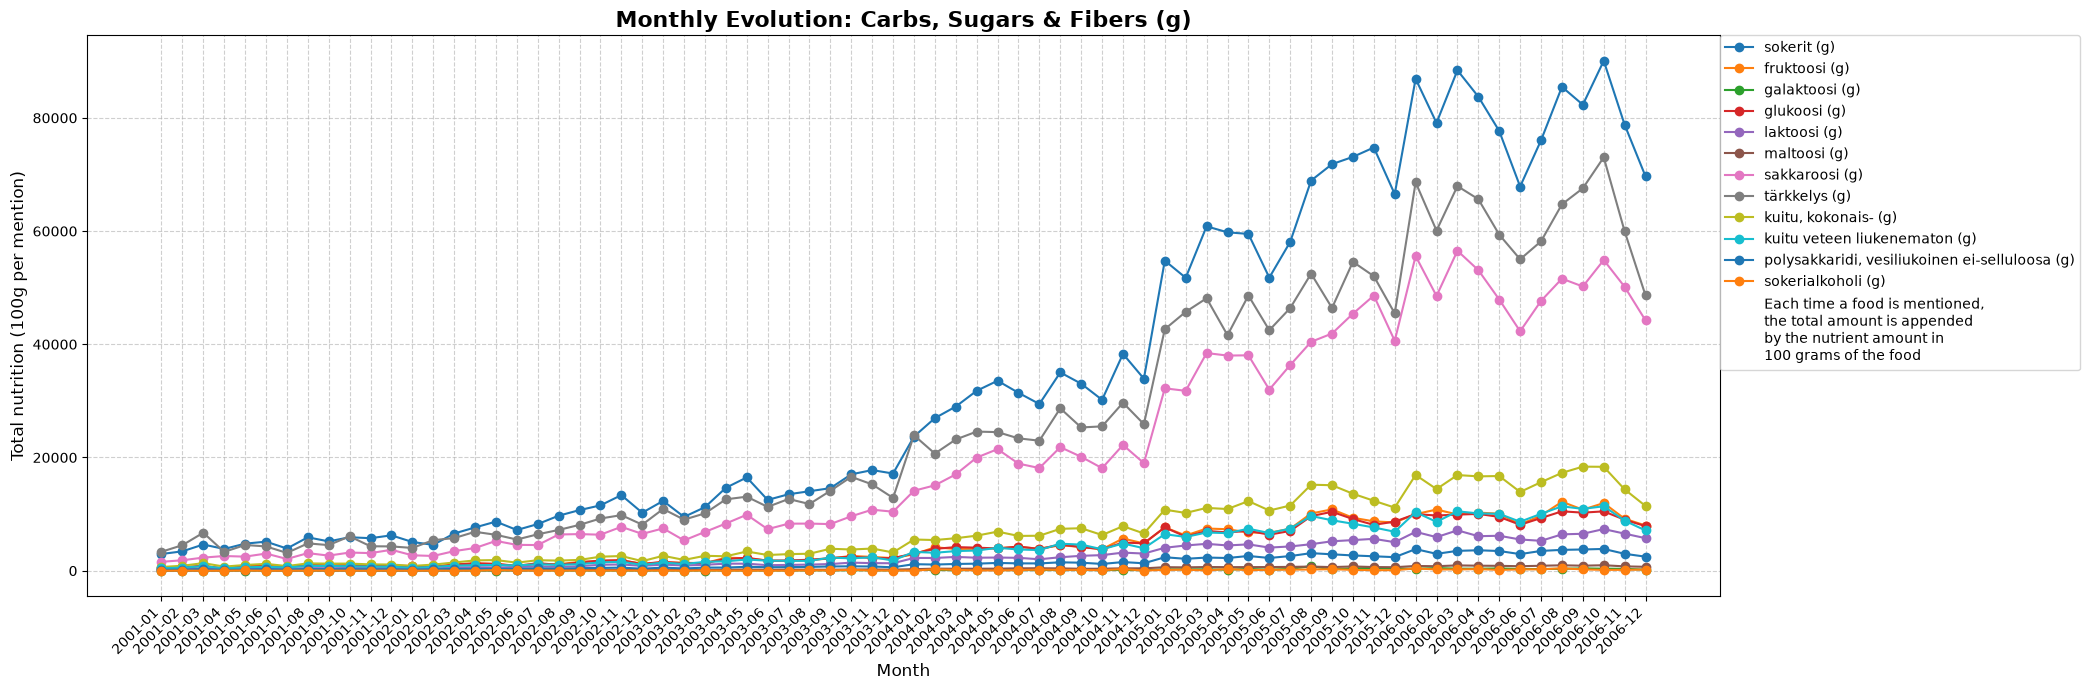

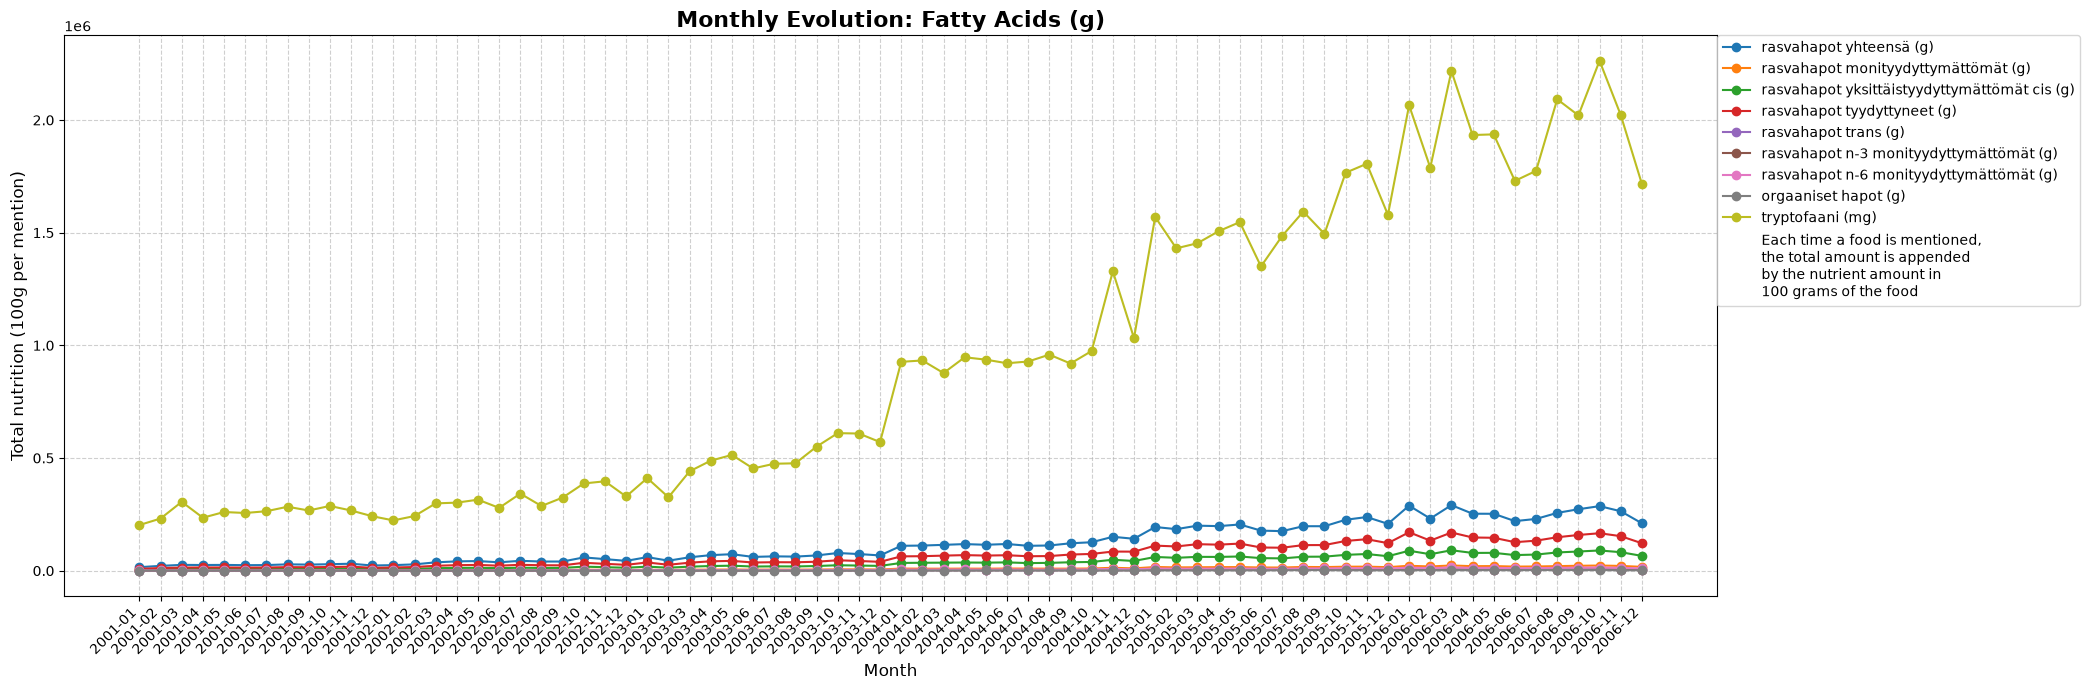

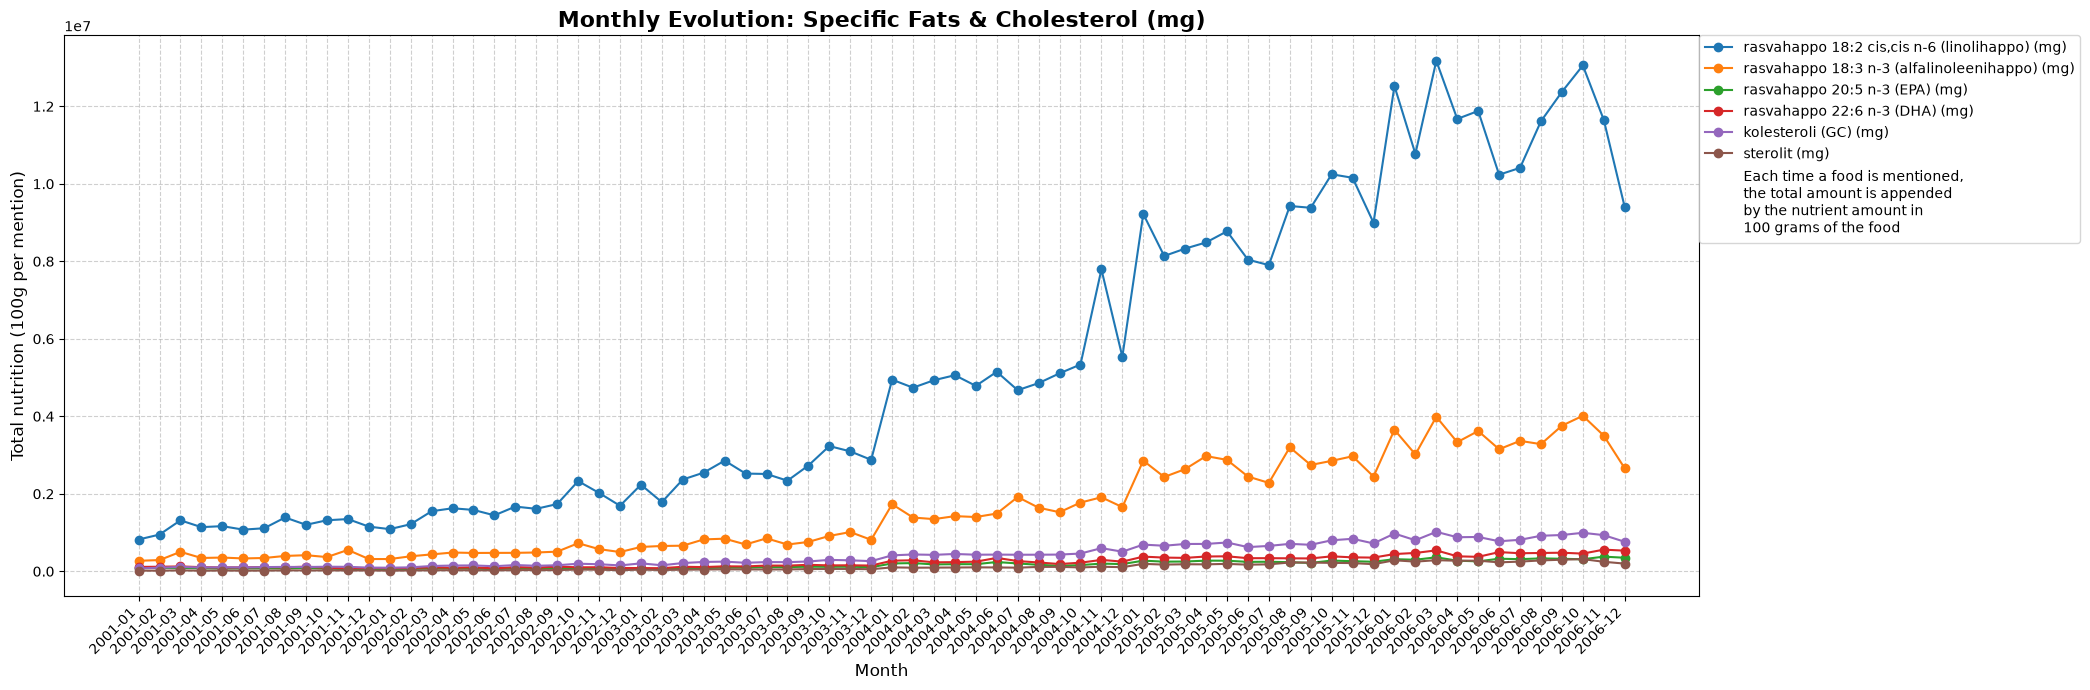

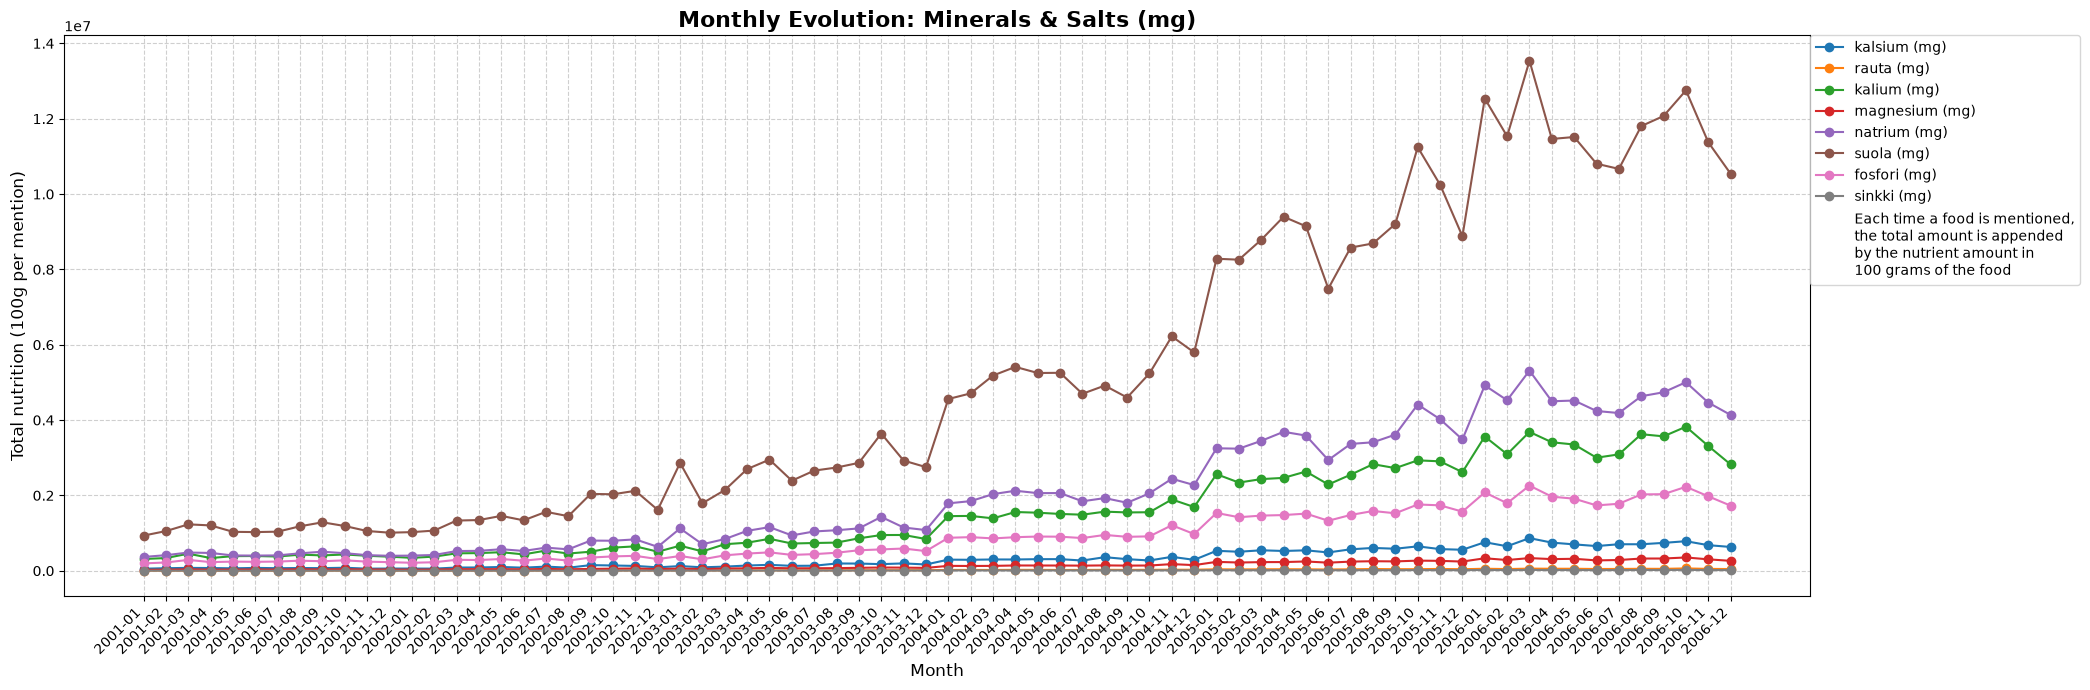

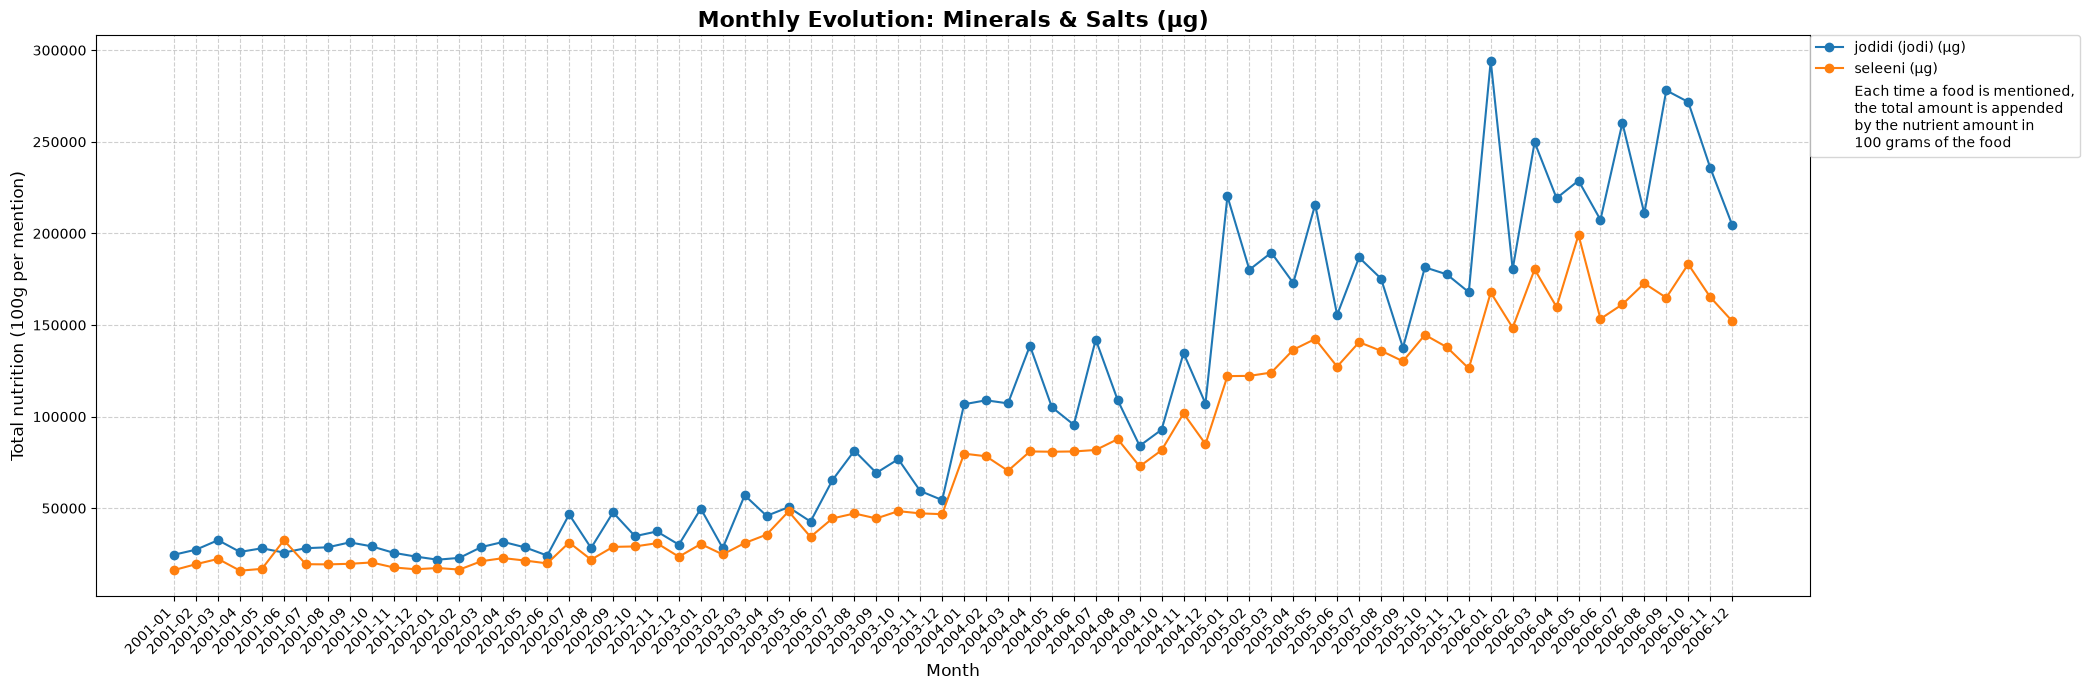

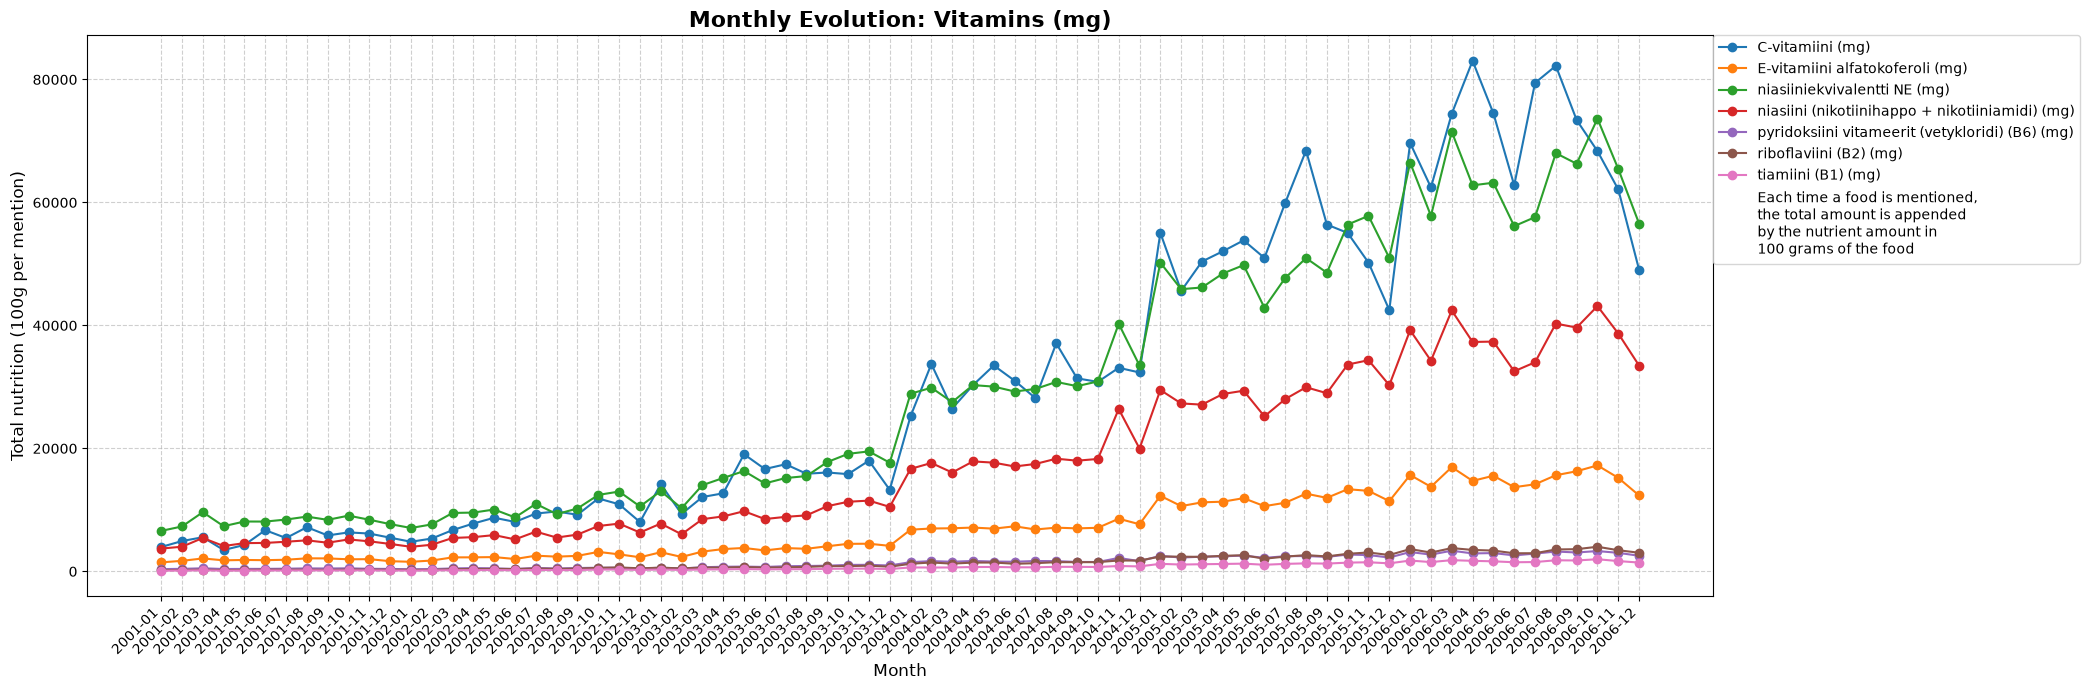

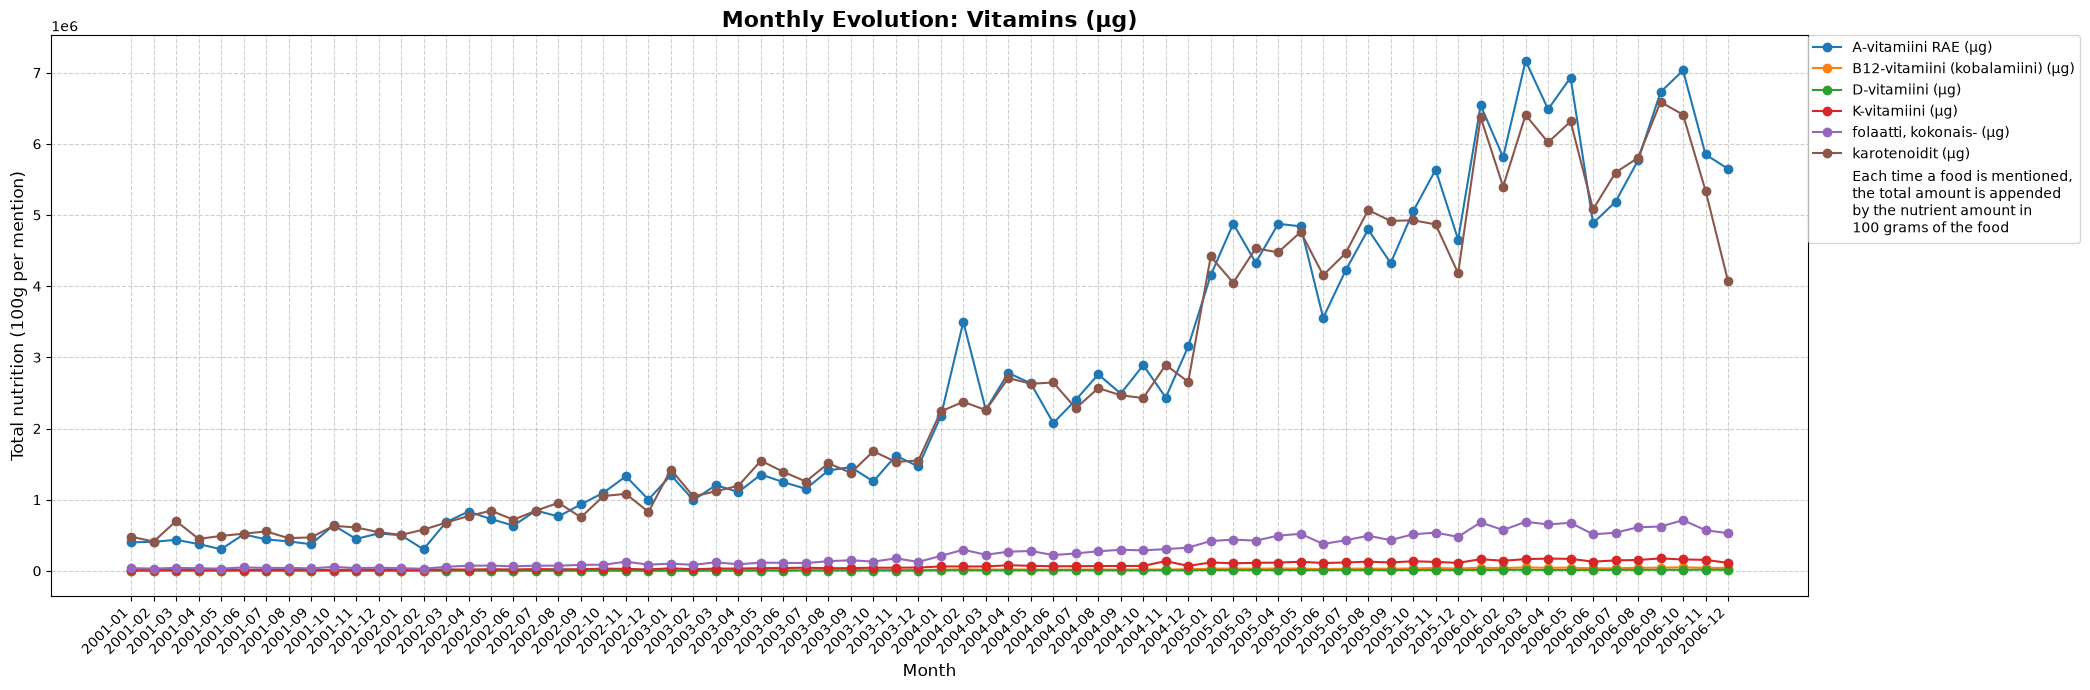

In [16]:
draw_monthly_nutrition_intake(monthly_nutrition_df)

In [56]:
# Look at one saved record
first_file = sorted(glob.glob(str(OUT_DIR / "*.jsonl.gz")))[0]
with gzip.open(first_file, "rt", encoding="utf-8") as f:
    first = None
    for line in f:
        last = json.loads(line)
        break
print(json.dumps(last, ensure_ascii=False, indent=2))



{
  "thread_id": "8471",
  "topic": "Ryhmät > Ikäryhmät > 40 plus",
  "date": "2001-01-01",
  "month": "2001-01",
  "title": "uudenvuodenlupaukset",
  "title_lemmas": "uudenvuodenlupaus",
  "title_n_tokens": 1,
  "title_n_chars": 20,
  "n_comments": 6,
  "foods": {
    "kalja": 1
  },
  "foods_in_title": [],
  "messages": [
    {
      "idx": 5,
      "date": "2001-01-09",
      "text": "Lupasin itselleni kesään mennessä siirtyä kaljasta lonkeroon .",
      "lemmas": "luvata itse kesä mennessä siirtyä kalja lonkero .",
      "foods": {
        "kalja": 1
      }
    }
  ]
}


In [57]:
print("\nDistinct foods found:", counts.shape[1])
print(counts.sum().nlargest(25))


Distinct foods found: 758
food
voi        74149
vesi       52152
kieli      37637
tee        35684
sydän      25894
kala       23856
veri       18698
kani       18108
viina      16181
liha       15658
kahvi      13334
maito      10719
olut        8134
kurkku      7652
kalja       7391
kana        7330
maksa       6255
sokeri      6130
rapu        5852
viini       5834
hedelmä     5777
keksi       5254
munkki      5213
herne       5201
peruna      4606
dtype: int64


In [ ]:
def load_titles():
    rows = []
    for p in sorted(glob.glob(str(OUT_DIR / "*.jsonl.gz"))):
        with gzip.open(p, "rt", encoding="utf-8") as f:
            for line in f:
                r = json.loads(line)
                rows.append((r["month"], r["date"], r["thread_id"],
                             r["title"], r["title_lemmas"], r["foods"], len(r["foods"])))
    return pd.DataFrame(rows, columns=["month", "date", "thread_id",
                                       "title", "title_lemmas", "foods", "n_foods"])


titles_df = load_titles()
# titles_df.to_csv("datasets/titles_by_month.csv.gz", index=False)
monthly_titles = {month: g for month, g in titles_df.groupby("month")}

print(len(titles_df), "titles in", len(monthly_titles), "months\n")
print(monthly_titles[sorted(monthly_titles)[0]].head())

337283 titles in 72 months

     month        date thread_id                             title  \
0  2001-01  2001-01-01      8471              uudenvuodenlupaukset   
1  2001-01  2001-01-01     57493               Virikkeitä kanille?   
2  2001-01  2001-01-01     50326  Flubenolista suomeksi!!! by Cory   
3  2001-01  2001-01-01    104216       SATAKUNTA ON HIENO MAAKUNTA   
4  2001-01  2001-01-01      7048                     tupakkakielto   

                     title_lemmas  n_foods  
0               uudenvuodenlupaus        1  
1                   virike kani ?        2  
2  flubenolista suomi !!! by cory        1  
3   satakunta olla hieno maakunta        2  
4                   tupakkakielto        1  
